# Lesson 4: Track what is possible
## Fruit Feast

Run in Jupyter or Google Colab with Python 3. No packages or external input files are required. Shift+Enter runs a cell. Run the setup cell first. Predict each result before running code.

Exercise IDs match the worksheet and slides. Small recursive examples are for learning; use iteration for large inputs. Python stops recursion at about 1,000 nested calls by default, so recursive versions are for small inputs only.

Where a question asks you to write a program, the cell below it is a stub: replace `return None` with your code, then run the check cell. Cells marked **Worked example** explain an idea; read them after you have tried the question.


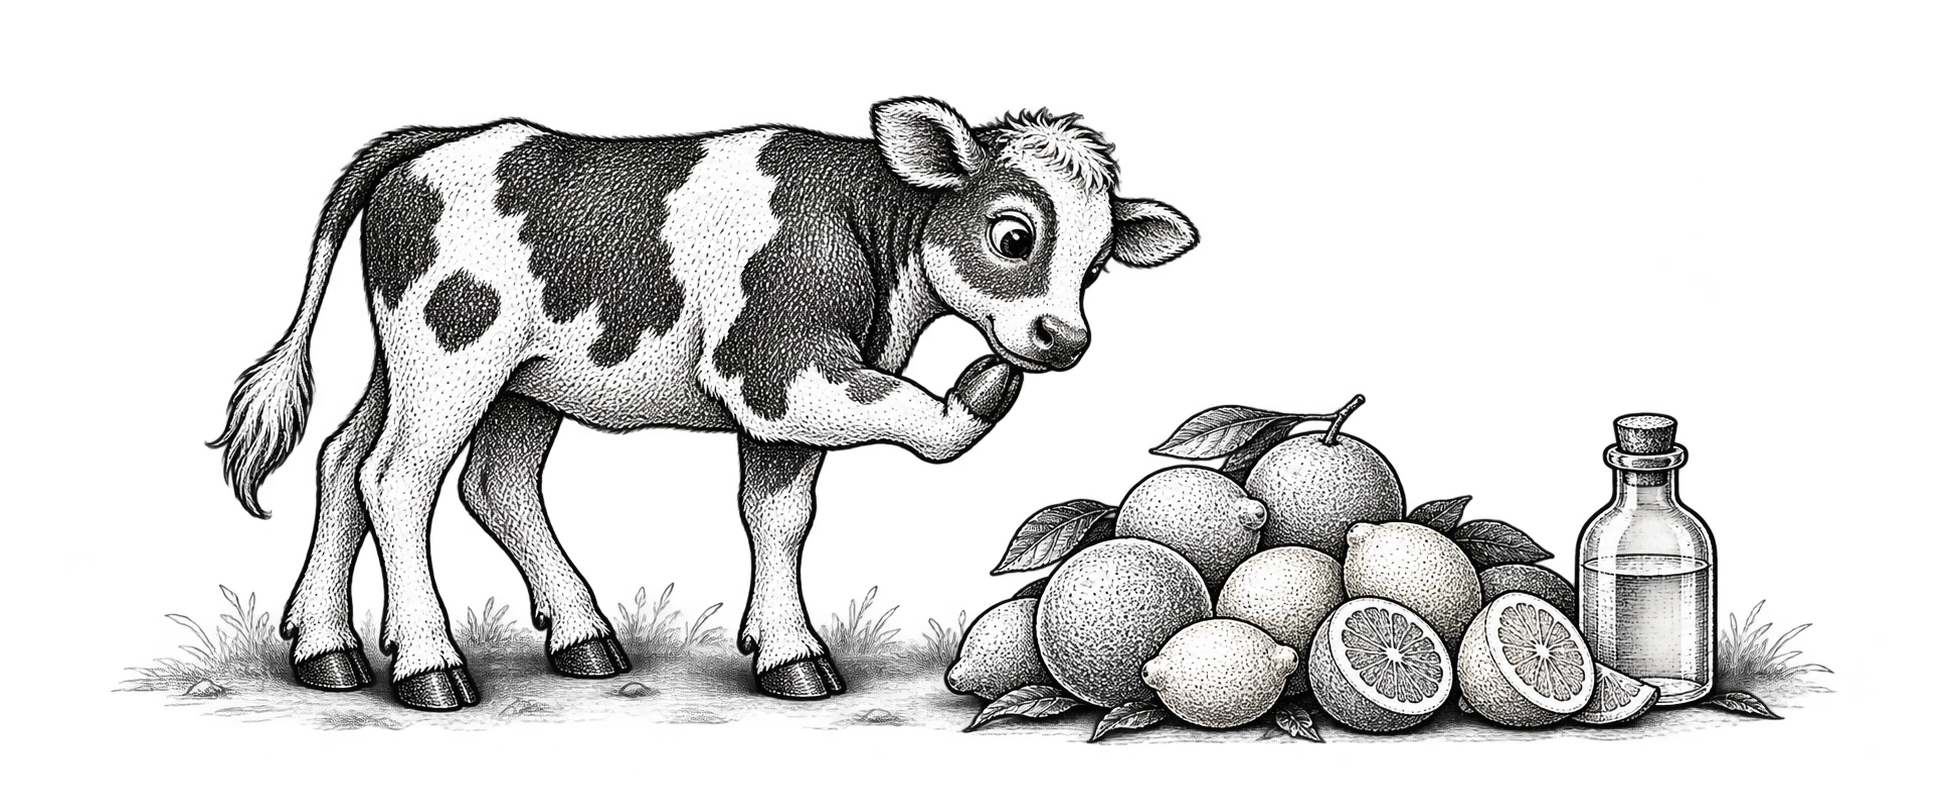

In [ ]:
from functools import lru_cache
print('Ready. Run cells from top to bottom.')


## The route and the rules

### Our route
First find all fullness values reachable without water. Next consider drinking from each of those values. Finally add fruit after the drink. Keep these three lists of results separate while tracing the example; they represent different moments in the calculation.

### Fruit Feast rules
The cow starts with fullness 0. There is unlimited fruit: one type adds a and the other adds b, both positive integers. Fullness must never exceed limit. A fruit that would exceed limit cannot be eaten. The cow may stop at any time; find the largest fullness she can reach.

### The one drink
Water is optional and can be used at most once, before, between or after eating. It changes fullness f to `f // 2`, where // rounds down. For example, 5 becomes 2. Fruit may be eaten afterwards, but a second drink is forbidden.

### Names used in the questions
`dry[f]` says whether fullness f is reachable without having used water. `wet[f]` says whether it is reachable after using water. The position f is a fullness value. The entry is a yes/no flag, not a count of routes. Write Y for reachable and - for unreachable in the printed tables.

### Recursion and the table answer different questions
The recursive function returns the largest final fullness reachable from the current situation. The iterative tables store which situations can be reached from the start. Both must obey the same fruit and water rules. When tracing, always label which kind of answer you are recording.

## L4-01: Eating without going over

Fullness starts at 0 and must never exceed 10. An orange adds 4 and a lemon adds 7. You may eat either fruit repeatedly. Without water, what fullness values are reachable?

**Your prediction / reasoning:**

Write your explanation here.

## L4-02: Water can make room

At most once, the cow may drink water. Water halves the current fullness, rounding down. With limit 10 and fruit sizes 4 and 7, find a route to fullness 10.

**Your prediction / reasoning:**

Write your explanation here.

## L4-03: Same fullness, different choices

A reachability flag is a yes/no answer: can the cow reach this situation? Compare fullness 4 with water still unused and fullness 4 after drinking. Do they allow the same next actions? Why would one flag called reachable[4] lose information we need?

**Your prediction / reasoning:**

Write your explanation here.

## L4-04: A small recursive search

Write feast_cached(limit, a, b) using cached recursion. The helper asks: from fullness f, with used_water saying whether the drink has been used, what is the greatest final fullness reachable? List every legal next action, including stopping. Explain why f and used_water belong in the cache key.

**Start with:**

```python
def feast_cached(limit, a, b):
    def best(fullness, used_water):
        return None  # Your helper goes here.
    return best(0, False)
```

**What each function returns:**
- `feast_cached(limit, a, b)`: the greatest reachable fullness, starting empty with water unused.
- `best(fullness, used_water)`: the greatest final fullness reachable from this fullness and water status.

**Hints:**
- Stopping is always allowed. What does that give as a first answer?
- Which moves are legal from (fullness, used_water)?
- Which move changes used_water, and can it happen twice?


**Your prediction / reasoning:**

Write your explanation here.

**Recursion depth:** Python stops recursion at about 1,000 nested calls by default, so this recursive version is for small inputs and the small and edge test files only. Use the iterative version for the medium and large files.

In [ ]:
def feast_cached(limit, a, b):
    """
    Return the greatest fullness reachable without exceeding limit,
    eating fruit a or b any number of times and drinking water (fullness
    // 2) at most once. Use a cached recursive best(fullness,
    used_water).
    """
    def best(fullness, used_water):
        # Returns the greatest final fullness reachable from this fullness and water status.
        # Write this helper here.
        return None
    return best(0, False)


In [ ]:
checks = [
    (feast_cached(10, 4, 7), 10),
    (feast_cached(9, 4, 6), 9),
    (feast_cached(15, 8, 9), 13),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

Include the option to stop: the current fullness is already a possible answer.

## L4-05: First, all fullness values before water

For limit 10 and fruit sizes 4 and 7, fill dry[0] through dry[10]. Why can the scan run from low fullness to high fullness?

Fullness f | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
dry[f] | Y | ? | ? | ? | ? | ? | ? | ? | ? | ? | ?

**Your prediction / reasoning:**

Write your explanation here.

## L4-06: Then, drink from every dry state

Take every fullness you marked as reachable without water in L4-05. Halve each one, rounding down, to find the states immediately after drinking and before any further fruit. Why would drinking only from the largest dry value miss a useful possibility?

**Your prediction / reasoning:**

Write your explanation here.

## L4-07: Finally, eat after water

Start from the values you found in L4-06 immediately after drinking. Fruit adds 4 or 7 and the limit is 10. Mark every fullness reachable after any further fruit, including no further fruit. A second drink is forbidden. What is the largest reachable fullness?

Fullness f | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
wet[f] | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

## L4-08: The complete three-pass program

Write feast_table(limit, a, b) with three passes: eat before water, drink once from each reachable value, then eat after water. A bytearray is a compact list of integers, initially all 0. Use 1 for reachable states. Explain the two arrays, scan order and choice of final answer.

**Start with:**

```python
def feast_table(limit, a, b):
    return None  # Replace with your answer.
```

**What each function returns:**
- `feast_table(limit, a, b)`: the greatest reachable fullness, starting empty with water unused.

**Hints:**
- Which fullness is reachable before anything is eaten?
- Keep the three passes in order: eat, drink once, eat again.
- Which array does each pass read, and which does it write?


**Your prediction / reasoning:**

Write your explanation here.

In [ ]:
def feast_table(limit, a, b):
    """
    Return the same answer as feast_cached with three passes over two
    bytearrays, dry and wet: eat before water, drink once, then eat
    after water.
    """
    # Replace this return with your solution.
    return None


In [ ]:
checks = [
    (feast_table(10, 4, 7), 10),
    (feast_table(15, 8, 9), 13),
    (feast_table(10000, 2527, 2945), 9889),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All checks passed.')


**After completing the function:** Explain why each checked answer follows from the state and its earlier answers.

Keep the water-transfer loop between the two eating loops.

## L4-09: Your turn: a different feast

Use limit 9 and fruit sizes 4 and 6. Mark three rows: reachable without water; immediately after drinking; after any further fruit. Keep the water-only row separate from the completed wet row. Give a route to the largest final fullness. Test your feast_table(limit, a, b) from L4-08 on this example.

Fullness f | 0 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9
--- | --- | --- | --- | --- | --- | --- | --- | --- | --- | ---
dry[f] | Y | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;
just drank | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;
wet[f] | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp; | &nbsp;

**Your prediction / reasoning:**

Write your explanation here.

**Use your `feast_table` from L4-08.** If you change it, run its cell again before the checks below.

In [ ]:
checks = [
    (feast_table(9, 4, 6), 9),
    (feast_table(10, 4, 7), 10),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L4-10: Boundary tests and optional water

Test your feast_table(limit, a, b) from L4-08. Here limit is maximum fullness, and a and b are the fruit increases. First predict the answers for (1, 1, 1), (8, 4, 6) and (5, 4, 4), then run your function. Must the cow drink? Give a route for each answer.

**Your prediction / reasoning:**

Write your explanation here.

**Use your `feast_table` from L4-08.** If you change it, run its cell again before the checks below.

In [ ]:
checks = [
    (feast_table(1, 1, 1), 1),
    (feast_table(8, 4, 6), 8),
    (feast_table(5, 4, 4), 4),
]
if any(actual is None for actual, expected in checks):
    print('Not implemented yet. Complete the function above.')
else:
    for number, (actual, expected) in enumerate(checks, 1):
        assert actual == expected, ('check', number, 'expected', expected, 'got', actual)
    print('All exercise checks passed.')


## L4-11: Explain why the pass order works

Why must all states reachable without water be found before we halve them, and all immediate-after-water states be marked before we add more fruit? Use the path 0 to 7, drink to 3, then add 7 as an example of the required order.

**Your prediction / reasoning:**

Write your explanation here.

## Original problem sources
- [Fruit Feast - USACO December 2015 Gold, problem 2](https://www.usaco.org/index.php?page=viewproblem2&cpid=574)